# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Raghavan 2021's PDAC malignant manifold is **non-branching**: the three embryonic signatures
collapse onto a **single dominant axis** — gastrulation/somitogenesis (Gast/pSom) high over the
classical-ductal body opposed to neural-crest (Crest) at a terminal end — rather than a hub
radiating to discrete arms with cross-repression. Critically, Gast and pSom **co-vary** here
(smoothed spatial r ≈ +0.32) rather than diverging into opposing arms, and both oppose Crest
(r ≈ −0.80 / −0.69). That is the non-branching signature (task §1), *not* the Puram branching
signature (Gast↔pSom mutual exclusivity). The correct topology is therefore a **principal curve**
(ElPiGraph, non-branching by construction) fit on the *joint* embedding — **not** a re-embedding
(re-embedding an anisotropic strip fabricates folds).

**A branching temptation, resolved on the data.** Raghavan defined the classical↔basal-like
plasticity axis, so a Y-shaped classical/basal split is plausible *a priori*. We test it directly:
the classical and basal signatures do form a real opposed axis (smoothed r ≈ −0.70), **but it is
orthogonal to the embryonic modules** (pSom vs classical/basal r ≈ +0.04 / +0.05). The classical/
basal axis is therefore not the embryonic-developmental axis the gates concern; forcing a tree onto
it would answer a different question. Judged on the embryonic-signature geography, the developmental
object is a single gradient. The curve is rooted at the Gast/pSom-high tip and pseudotime flows to
the neural-crest terminus. Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
ds   = name[:-2] if name.endswith('-4') else name
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
Keep all cells on their *original joint embedding coordinates* — no re-embedding. The three
embryonic signatures are scored against the shared **union** control pool and graph-smoothed
(knn-connectivity averaging) to read geography rather than Seq-Well per-cell dropout. Raw means are
reported as the honest scalar readout; geography and gate calls use the smoothed fields.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']
from numpy.linalg import svd
c = xy - xy.mean(0); u,s,vt = svd(c, full_matrices=False)
print(f'UMAP principal-axis ratio (major/minor singular value): {s[0]/s[1]:.2f}')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('raw module means (honest readout):',
      adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

whole malignant manifold: 7168 cells on the joint embedding
UMAP principal-axis ratio (major/minor singular value): 1.18
Gast: 73/81 genes present
pSom: 85/98 genes present
Crest: 103/104 genes present
raw module means (honest readout): {'Gast': -0.0076, 'pSom': 0.0711, 'Crest': -0.0216}


### Scope decision — whole manifold vs one lobe (data-driven)
Test whether the developmental axis is confined to one lobe (the Kürten case, where scoping is
justified because a cycling lobe confounds Gast) or spans the whole manifold (Bischoff/Sun/Lee/
Steele case). Three facts settle it for Raghavan PDAC: (i) the smoothed embryonic signatures form
one axis — Gast/pSom co-vary and both oppose Crest; (ii) the classical/basal plasticity axis is
orthogonal to the embryonic modules, so it is a *different* biological axis, not a developmental
bifurcation; (iii) **cell cycle is not a confound** — the developmental modules correlate
negligibly with a cycling score (|rho| ≤ 0.20; the decisive pSom axis at −0.04) and pseudotime is
essentially uncorrelated with cycling (rho ≈ +0.15). The small cycling lobe is ~11% of cells and
does not define the embryonic axis. Unlike Kürten there is no proliferation-confounded Gast lobe to
excise, so the whole manifold is the honest developmental object (no scoping).

In [4]:
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
# classical/basal plasticity axis vs embryonic modules (is the branching temptation the dev axis?)
Acl = adata.obs[['classical_score','basal_score']].values.copy()
for _ in range(3): Acl = A @ Acl
adata.obs['cl_sm'], adata.obs['bs_sm'] = Acl[:,0], Acl[:,1]
print('classical/basal plasticity axis (smoothed):')
print(f"  classical vs basal: r = {np.corrcoef(adata.obs['cl_sm'],adata.obs['bs_sm'])[0,1]:+.2f} (real opposed axis)")
for m in ['pSom_sm','Gast_sm','Crest_sm']:
    rc = np.corrcoef(adata.obs[m], adata.obs['cl_sm'])[0,1]
    rb = np.corrcoef(adata.obs[m], adata.obs['bs_sm'])[0,1]
    print(f'  {m} vs classical/basal: r = {rc:+.2f} / {rb:+.2f}')
print('  -> classical/basal axis is orthogonal to the embryonic modules (not the developmental axis)')
print('\nper-lobe smoothed developmental means (compartment):')
print(adata.obs.groupby('compartment', observed=True)[['Gast_sm','pSom_sm','Crest_sm']].mean().round(4).to_string())
# proliferation-vs-module confound check
g1s = pd.to_numeric(adata.obs['g1s_score'], errors='coerce').fillna(0).values
g2m = pd.to_numeric(adata.obs['g2m_score'], errors='coerce').fillna(0).values
cyc = np.maximum(g1s, g2m)
print('\ncell-cycle confound check (Spearman rho vs raw module):')
for m in ['Gast','pSom','Crest']:
    rho,_ = spearmanr(cyc, adata.obs[m].values); print(f'  {m} vs cycling score: rho = {rho:+.2f}')
print('-> developmental axis orthogonal to proliferation; keep whole manifold (no scoping).')
sub = adata

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = +0.32
  Crest_sm vs Gast_sm: r = -0.80
  Crest_sm vs pSom_sm: r = -0.69
classical/basal plasticity axis (smoothed):
  classical vs basal: r = -0.70 (real opposed axis)
  pSom_sm vs classical/basal: r = +0.04 / +0.05
  Gast_sm vs classical/basal: r = +0.51 / -0.56
  Crest_sm vs classical/basal: r = -0.25 / +0.38
  -> classical/basal axis is orthogonal to the embryonic modules (not the developmental axis)

per-lobe smoothed developmental means (compartment):
                  Gast_sm  pSom_sm  Crest_sm
compartment                                 
Basal-like        -0.0093   0.0623   -0.0183
Classical-ductal  -0.0022   0.0779   -0.0272
Cycling           -0.0370   0.0639   -0.0058

cell-cycle confound check (Spearman rho vs raw module):
  Gast vs cycling score: rho = -0.20
  pSom vs cycling score: rho = -0.04
  Crest vs cycling score: rho = +0.11
-> developmental axis orthogonal to proliferation; keep whole mani

### Fit the principal curve (ElPiGraph)
`Nodes/epg_lambda/epg_mu` give a **fold-free** monotone backbone: a node self-approach ratio > 1
(minimum distance between graph-non-adjacent nodes, in units of median edge length) certifies the
curve does not fold back on itself. Node count (15) is scaled down for this ~7k-cell strip (fewer
nodes than a large 10x set to avoid over-articulating a smooth arc); `epg_mu=100` is strong bending
regularisation. The fold diagnostic is checked across a small Nodes sweep before committing.

In [5]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

print('fold-free node sweep:')
for N in [15, 20, 25]:
    ad2 = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(ad2, Nodes=N, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa,tips,forks = fold_diag(ad2)
    print(f'  Nodes={N}: tips={tips} forks={forks} self-approach={sa:.2f}')
Nodes = 15
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=Nodes, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'chosen Nodes={Nodes}: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

fold-free node sweep:
  Nodes=15: tips=2 forks=0 self-approach=2.97
  Nodes=20: tips=2 forks=0 self-approach=2.70
  Nodes=25: tips=2 forks=0 self-approach=2.38
chosen Nodes=15: 2 tips, 0 forks | fold self-approach ratio = 2.97 (>1 = fold-free)


### Derive the root (data-driven)
The root is the curve tip where Gast+pSom is highest and Crest lowest — the developmental origin
(Gast/pSom-high classical-ductal body). Pseudotime then flows to the neural-crest terminus. Crest
is developmentally *late*, so it is never the root (task trajectory rules).

In [6]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')
tn = (t-t.min())/(t.max()-t.min())
for m,lab_ in [('Crest_sm','Neural-crest'),('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation')]:
    hi = sub.obs[m] >= sub.obs[m].quantile(0.9)
    print(f'{lab_}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')

tip 0: Gast=-0.0016 pSom=+0.0819 Crest=-0.0303
tip 2: Gast=-0.0125 pSom=+0.0619 Crest=-0.0173
derived root = tip 0 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.439 p=0.0e+00
  pSom_sm: rho=-0.698 p=0.0e+00
  Crest_sm: rho=+0.594 p=0.0e+00
Neural-crest-high decile mean pseudotime = 0.68
Somitogenesis-high decile mean pseudotime = 0.08
Gastrulation-high decile mean pseudotime = 0.05


### House orientation (re-used from 01, verified against pseudotime)
The house orientation — a single rigid rotation of the diagonal developmental axis to horizontal,
Gast/pSom-high origin on the left — was derived **once in 01** and stored as `X_umap_lin`. Every
UMAP deliverable across 01–04 re-uses these exact coordinates, so orientation is consistent by
construction. Here we **verify** it now that pseudotime exists: the correlation of the stored
`X_umap_lin` x-axis with pseudotime must be strongly positive (low pseudotime = origin on left).

In [7]:
t = sub.obs['t'].values
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
assert r > 0.5, f'stored orientation not pseudotime-consistent (corr={r:.2f})'
print(f'house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = {r:+.2f}')

house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = +0.97


### Save manifold + trajectory figure (deliverable)
`manifold.pdf` renders the **fitted curve edges** over the cells (task-binding: topology and
fold-freeness must be visually verifiable), coloured by pseudotime, in the house orientation.

saved manifold.h5ad + manifold.pdf (curve edges + green root star rendered)


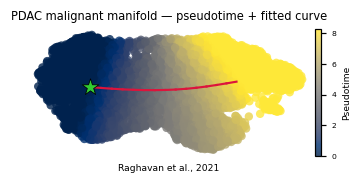

In [8]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
# node coords transformed into the house (X_umap_lin) frame for edge overlay
F = sub.uns['graph']['F'].T
xym = sub.obsm['X_umap']; cc = xym - xym.mean(0)
_,_,vt = np.linalg.svd(cc, full_matrices=False)
th_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-th_rot),-np.sin(-th_rot)],[np.sin(-th_rot),np.cos(-th_rot)]])
Fr = (F - xym.mean(0)) @ Rm.T
# match the sign flip 01 applied (origin pole on the left)
flip = np.corrcoef(((cc@Rm.T)[:,0]), sub.obsm['X_umap_lin'][:,0])[0,1] < 0
if flip: Fr[:,0] = -Fr[:,0]
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sca = ax.scatter(xl[:,0], xl[:,1], c=t, cmap='cividis', s=30, alpha=.8, linewidths=0)
Bm = np.asarray(sub.uns['graph']['B']); ii,jj = np.where(np.triu(Bm>0))
for a,b in zip(ii,jj):
    ax.plot([Fr[a,0],Fr[b,0]],[Fr[a,1],Fr[b,1]], '-', color='crimson', lw=1.4, zorder=4)
ax.scatter(Fr[root,0], Fr[root,1], marker='*', s=130, color='limegreen',
           edgecolor='k', linewidths=.5, zorder=5)
cb = fig.colorbar(sca, ax=ax, fraction=.045, pad=.02); cb.set_label('Pseudotime', size=6)
cb.ax.tick_params(labelsize=5)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py); ax.axis('off')
ax.set_title('PDAC malignant manifold — pseudotime + fitted curve', size=7.5)
ax.text(.5,-.12,'Raghavan et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf (curve edges + green root star rendered)')